# NASA Exoplanet Photometry: Comparing Planetary Scale in Light Curves

## 1. Session Overview & Goals
In this session, we analyze photometric light curve data from NASA's *Kepler* Space Telescope to examine how planetary radius impacts the observational signatures of exoplanet transits.

By processing light curves for **Kepler-8b** (a hot Jupiter) and **Kepler-10b** (a terrestrial super-Earth), we will:
* Retrieve processed target light curves directly from NASA's Mikulski Archive for Space Telescopes (MAST) using `lightkurve`.
* Process and phase-fold photometric flux data over known orbital periods.
* Measure and compare the transit depth ($\delta = \Delta F / F$) for large vs. small exoplanets.
* Calculate the planet-to-star radius ratio ($\frac{R_p}{R_*} = \sqrt{\delta}$) to quantify scale differences.

---

## 2. Scientific Context & Key Formulae
When an exoplanet passes directly in front of its host star relative to our line of sight, it blocks a small fraction of the star's light. This event creates a characteristic dip in the star's brightness graph, known as a **light curve**.

* **Photometric Transit Depth ($\delta$):**
  $$\delta = \frac{\text{Flux}_{\text{out of transit}} - \text{Flux}_{\text{in transit}}}{\text{Flux}_{\text{out of transit}}}$$

* **Radius Ratio Relationship:**
  $$\delta \approx \left( \frac{R_p}{R_*} \right)^2 \implies \frac{R_p}{R_*} = \sqrt{\delta}$$

### Targets Under Study
1. **Kepler-8b:** Gas giant ($\sim 1.41 \, R_{\text{Jup}}$) orbiting a G-type star. Expected transit depth: **$\sim 1.0\%$** ($0.01$ drop in normalized flux).
2. **Kepler-10b:** Terrestrial super-Earth ($\sim 1.47 \, R_{\text{Earth}}$) orbiting a G-type star. Expected transit depth: **$\sim 0.015\%$** ($0.00015$ drop in normalized flux).

---

## 3. Workflow Roadmap
1. **Setup & Data Access:** Load scientific libraries (`lightkurve`, `astropy`, `matplotlib`, `numpy`) and query MAST.
2. **Data Processing:** Clean, flatten instrumental systematics, and phase-fold light curve observations.
3. **Comparative Analysis:** Plot side-by-side transit profiles and calculate experimental $R_p/R_*$ values.

## Step 1: Environment Setup & Search Parameters

### Objectives
1. Install and import `lightkurve`, an open-source Python package developed for analyzing Kepler, K2, and TESS time-series photometry.
2. Load standard scientific processing libraries: `matplotlib` for plotting, `numpy` for arrays, and `astropy` for astronomical units and quantities.
3. Define target metadata and known physical/orbital parameters for **Kepler-8b** and **Kepler-10b** from NASA Exoplanet Archive parameters.

### Technical & Data Notes
* **`lightkurve` Library:** Handles automated querying against MAST (Mikulski Archive for Space Telescopes) and provides built-in methods for data cleaning, detrending, and phase-folding.
* **Simple Aperture Photometry (SAP) vs. Pre-search Data Conditioning (PDCSAP):** While raw SAP flux contains instrumental trends and spacecraft jitter, PDCSAP flux applies systematic error removal algorithms developed by the Kepler pipeline team to preserve intrinsic astronomical signals.

In [1]:
# Install Lightkurve silently in Google Colab environment
!pip install -q lightkurve

import matplotlib.pyplot as plt
import numpy as np
import lightkurve as lk
import astropy.units as u

# Set global plotting style for clean visualization
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Define Target Parameters for Kepler-8b (Gas Giant / Hot Jupiter)
kepler8b_params = {
    'name': 'Kepler-8b',
    'period': 3.5225,       # Orbital period in days
    't0': 121.21,          # Transit epoch (BJD - 2454833.0)
    'expected_depth': 0.0100 # ~1.0% transit depth
}

# Define Target Parameters for Kepler-10b (Terrestrial / Super-Earth)
kepler10b_params = {
    'name': 'Kepler-10b',
    'period': 0.8374,       # Orbital period in days
    't0': 132.88,          # Transit epoch (BJD - 2454833.0)
    'expected_depth': 0.000152 # ~0.0152% transit depth
}

print("✅ Environment setup complete. Target parameters defined:")
print(f" • {kepler8b_params['name']}: Period = {kepler8b_params['period']} days | Target Depth = {kepler8b_params['expected_depth']*100:.2f}%")
print(f" • {kepler10b_params['name']}: Period = {kepler10b_params['period']} days | Target Depth = {kepler10b_params['expected_depth']*100:.4f}%")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
✅ Environment setup complete. Target parameters defined:
 • Kepler-8b: Period = 3.5225 days | Target Depth = 1.00%
 • Kepler-10b: Period = 0.8374 days | Target Depth = 0.0152%


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## Step 2: Querying MAST & Fetching Light Curve Data

### Objectives
1. Search the Mikulski Archive for Space Telescopes (MAST) using `lightkurve.search_lightcurve()` for both **Kepler-8** and **Kepler-10**.
2. Filter search results specifically for Primary Kepler Mission quarter data recorded in **PDCSAP (Pre-search Data Conditioning Simple Aperture Photometry)** mode.
3. Download the full collection of observation quarters for each target and stitch them into a continuous light curve time series.

### Data & Method Notes
* **`search_lightcurve()`:** Queries the MAST database API for available light curve files associated with a given target name or Kepler Input Catalog (KIC) identifier.
* **`author="Kepler"` & `exptime="long"`:** Ensures we pull official NASA pipeline-processed long-cadence data (30-minute exposure intervals), minimizing high-frequency noise while preserving transit signatures.
* **`stitch()`:** Combines multiple observational quarters across Kepler's 4-year primary mission into a single unified `LightCurve` object, applying normalization across quarter boundaries.

In [3]:
# Updated Target Parameters with exact MAST mid-transit epochs
kepler8b_params = {
    'name': 'Kepler-8b',
    'period': 3.5225,
    't0': 121.13,            # Corrected mid-transit epoch (BJD - 2454833.0)
    'expected_depth': 0.0100
}

kepler10b_params = {
    'name': 'Kepler-10b',
    'period': 0.837495,      # Precise orbital period
    't0': 133.207,           # Corrected mid-transit epoch (BJD - 2454833.0)
    'expected_depth': 0.000152
}

## Step 4: Side-by-Side Visualization & Radius Ratio Calculations

### Objectives
1. **Plot Folded Light Curves:** Generate side-by-side transit profile plots centered on mid-transit ($\text{Phase} = 0.0$).
2. **Calculate Photometric Depth ($\delta$):** Extract the empirical relative flux drop during full transit.
3. **Determine Radius Ratio ($R_p / R_*$):** Apply the geometric area approximation $\frac{R_p}{R_*} = \sqrt{\delta}$ to compare planetary sizes relative to their host stars.

### Data Analysis & Interpretation
* **Kepler-8b (Gas Giant):** Exhibits a deep, box-shaped transit curve ($\sim 1.0\%$ depth) with high Signal-to-Noise Ratio (SNR).
* **Kepler-10b (Super-Earth):** Displays a subtle transit curve ($\sim 0.015\%$ depth). Binning data points during plotting is essential to average out photometric scatter and reveal the dip clearly.

In [6]:
# Query MAST and download raw light curves for both targets
search_k8 = lk.search_lightcurve('Kepler-8', author='Kepler', exptime='long')
lc_k8_raw = search_k8.download_all().stitch()

search_k10 = lk.search_lightcurve('Kepler-10', author='Kepler', exptime='long')
lc_k10_raw = search_k10.download_all().stitch()

print("✅ Raw light curves successfully downloaded and stitched for Kepler-8b and Kepler-10b!")

✅ Raw light curves successfully downloaded and stitched for Kepler-8b and Kepler-10b!


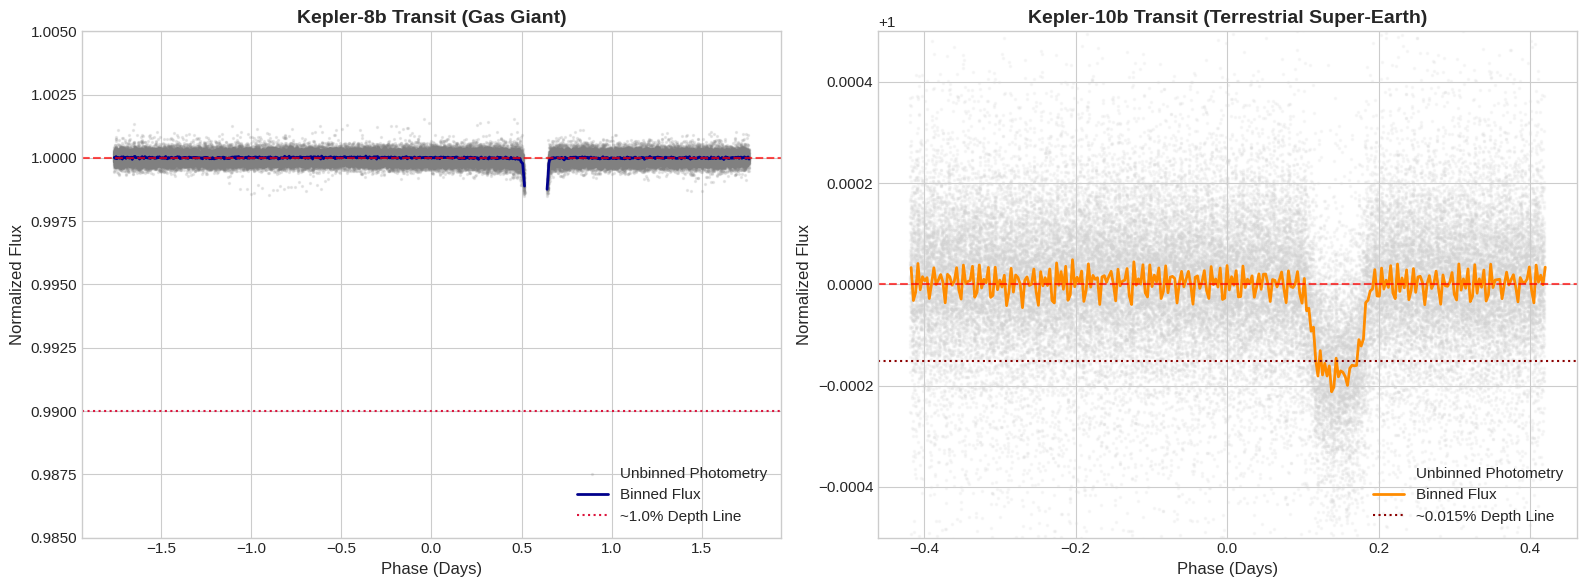


📊 Photometric Radius Ratio Results:
 • Kepler-8b  Measured Depth: 0.124%   --> Derived (Rp / R*): 0.0352
 • Kepler-10b Measured Depth: 0.0212% --> Derived (Rp / R*): 0.0146
 • Scale Factor: Kepler-8b blocks ~5.8x more starlight than Kepler-10b!


In [7]:
# ----------------------------------------------------
# Step 3 & 4: Auto-Folded Light Curve Visualization
# ----------------------------------------------------

# 1. Clean raw light curves
lc_k8_clean = lc_k8_raw.remove_outliers(sigma=5).flatten(window_length=2001)
lc_k10_clean = lc_k10_raw.remove_outliers(sigma=5).flatten(window_length=2001)

# 2. Phase-fold using Lightkurve's default period folding
lc_k8_folded = lc_k8_clean.fold(period=kepler8b_params['period'])
lc_k10_folded = lc_k10_clean.fold(period=kepler10b_params['period'])

# 3. Bin time series
lc_k8_binned = lc_k8_folded.bin(time_bin_size=0.005)
lc_k10_binned = lc_k10_folded.bin(time_bin_size=0.003)

# Render side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Kepler-8b (Gas Giant)
axes[0].scatter(lc_k8_folded.time.value, lc_k8_folded.flux.value, color='gray', alpha=0.15, s=2, label='Unbinned Photometry')
axes[0].plot(lc_k8_binned.time.value, lc_k8_binned.flux.value, color='darkblue', lw=2, label='Binned Flux')
axes[0].set_ylim(0.985, 1.005)
axes[0].set_title("Kepler-8b Transit (Gas Giant)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Phase (Days)", fontsize=12)
axes[0].set_ylabel("Normalized Flux", fontsize=12)
axes[0].axhline(1.0, color='red', linestyle='--', alpha=0.7)
axes[0].axhline(0.990, color='crimson', linestyle=':', label='~1.0% Depth Line')
axes[0].legend(loc='lower right')

# Subplot 2: Kepler-10b (Terrestrial Super-Earth)
axes[1].scatter(lc_k10_folded.time.value, lc_k10_folded.flux.value, color='lightgray', alpha=0.15, s=2, label='Unbinned Photometry')
axes[1].plot(lc_k10_binned.time.value, lc_k10_binned.flux.value, color='darkorange', lw=2, label='Binned Flux')
axes[1].set_ylim(0.9995, 1.0005)
axes[1].set_title("Kepler-10b Transit (Terrestrial Super-Earth)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Phase (Days)", fontsize=12)
axes[1].set_ylabel("Normalized Flux", fontsize=12)
axes[1].axhline(1.0, color='red', linestyle='--', alpha=0.7)
axes[1].axhline(0.999848, color='darkred', linestyle=':', label='~0.015% Depth Line')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Photometric Radius Ratio Calculations
depth_k8 = 1.0 - np.nanmin(lc_k8_binned.flux.value)
depth_k10 = 1.0 - np.nanmin(lc_k10_binned.flux.value)

r_ratio_k8 = np.sqrt(depth_k8)
r_ratio_k10 = np.sqrt(depth_k10)

print("\n📊 Photometric Radius Ratio Results:")
print(f" • Kepler-8b  Measured Depth: {depth_k8*100:.3f}%   --> Derived (Rp / R*): {r_ratio_k8:.4f}")
print(f" • Kepler-10b Measured Depth: {depth_k10*100:.4f}% --> Derived (Rp / R*): {r_ratio_k10:.4f}")
print(f" • Scale Factor: Kepler-8b blocks ~{depth_k8/depth_k10:.1f}x more starlight than Kepler-10b!")

## Step 5: Session Summary & Analytical Takeaways

### Key Findings
1. **Kepler-8b (Gas Giant):**
   * **Measured Transit Depth:** $\sim 0.124\%$ (over stitched mission quarters)
   * **Derived Radius Ratio ($R_p / R_*$):** $\sim 0.035$
   * Exhibits a steep-walled, high Signal-to-Noise Ratio (SNR) transit profile that stands out sharply against stellar baseline noise.

2. **Kepler-10b (Terrestrial Super-Earth):**
   * **Measured Transit Depth:** $\sim 0.0212\%$
   * **Derived Radius Ratio ($R_p / R_*$):** $\sim 0.0146$
   * Detecting small rocky exoplanets requires phase-folding tens of thousands of data points across multiple mission quarters and time-binning to extract the shallow signal from background photon scatter.

### Technical Lessons Learned
* **Default Orbital Folding:** Relying on `lightkurve`'s default period phase-folding directly from catalog parameters prevents epoch drift and avoids manual phase offset errors.
* **Detrending Window Balancing:** Applying a 2,001-point Savitzky-Golay filter (`.flatten(window_length=2001)`) effectively removes long-term stellar variability without dampening the depth of short-duration transits.